# 01 - Data Cleaning & Exploratory Analysis
**Project:** Abu Dhabi Real Estate Market Analysis

> **Data note:** this notebook runs on the *synthetic sample data* in `data/raw/`. Findings are illustrative, not real market facts. Swap in real data (Bayanat / Abu Dhabi Open Data / SCAD / Kaggle) and re-run.

**Business question:** Which areas offer the best value for buyers and renters, and how have prices changed over time?

**Notebook outline:** 1) load raw data, 2) profile quality issues, 3) clean, 4) explore, 5) takeaways.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

## 1. Load raw data

In [2]:
raw = pd.read_csv(ROOT / "data/raw/ad_sales_transactions_SAMPLE.csv")
print(raw.shape)
raw.head()

(43744, 8)


,transaction_id,transaction_date,area,property_type,bedrooms,size_sqm,price_aed,sale_type
0,122741,2024-06-12,Yas Island,Apartment,1,69.8,987000.0,Ready
1,100548,2021-02-15,Corniche Area,Townhouse,5,133.3,1573000.0,Off-Plan
2,136823,2025-11-22,Al Raha Beach,Apartment,1,51.1,786000.0,Ready
3,137998,2026-01-04,Corniche Area,Apartment,2,132.1,2482000.0,Off-Plan
4,134243,2025-09-09,KHALIFA CITY,Apartment,1,71.9,618000.0,Ready


## 2. Profile data quality issues

In [3]:
issues = pd.Series({
    "duplicate transaction_ids": raw["transaction_id"].duplicated().sum(),
    "missing price": raw["price_aed"].isna().sum(),
    "missing size": raw["size_sqm"].isna().sum(),
    "size < 20 sqm": (raw["size_sqm"] < 20).sum(),
    "non-ISO dates (dd/mm/yyyy)": raw["transaction_date"].str.contains("/").sum(),
    "distinct area spellings": raw["area"].nunique(),
})
issues.to_frame("count")

,count
duplicate transaction_ids,646
missing price,436
missing size,1301
size < 20 sqm,172
non-ISO dates (dd/mm/yyyy),1746
distinct area spellings,26


In [4]:
print(sorted(raw["area"].unique()))

['AL REEM ISLAND', 'Al Ghadeer', 'Al Maryah Island', 'Al Raha  Beach', 'Al Raha Beach', 'Al Raha Gardens', 'Al Reef', 'Al Reem Island', 'Corniche Area', 'KHALIFA CITY', 'Khalifa City', 'Khalifa City A', 'M.B.Z City', 'MBZ City', 'Masdar City', 'Mohamed Bin Zayed City', 'Mohammed Bin Zayed City', 'Raha Beach', 'Reem Island', 'SAADIYAT ISLAND', 'Saadiyat', 'Saadiyat Island', 'Yas', 'Yas Island', 'al reem island ', 'yas island']


**Observations**
- The same area appears under several spellings (e.g. *Reem Island*, *AL REEM ISLAND*), which would split totals in any `GROUP BY`.
- Duplicate IDs, missing values, impossible sizes, and mixed date formats are present.
- Some prices are far outside the normal range for their area (outliers, likely data-entry errors).

## 3. Clean
The full, reusable logic lives in `src/clean_data.py`. We run it here and inspect the result.

In [5]:
import sys; sys.path.insert(0, str(ROOT / "src"))
import clean_data
sales = clean_data.clean_sales()
rentals = clean_data.clean_rentals()
print("area names after cleaning:", sales["area"].nunique())

SALES raw rows: 43,744
  duplicates removed: 646


  unparseable dates: 0
  rows dropped for missing date/price/size: 1,702


  rows dropped for size < 20 sqm: 170
  price/sqm outliers removed: 205


SALES clean rows: 41,021

RENTALS raw rows: 14,900
RENTALS clean rows: 14,900
area names after cleaning: 12


**Before vs after:** rows lost at each step are printed above. We keep a log so the cleaning is auditable.

## 4. Exploratory analysis

### 4.1 Price per sqm by area

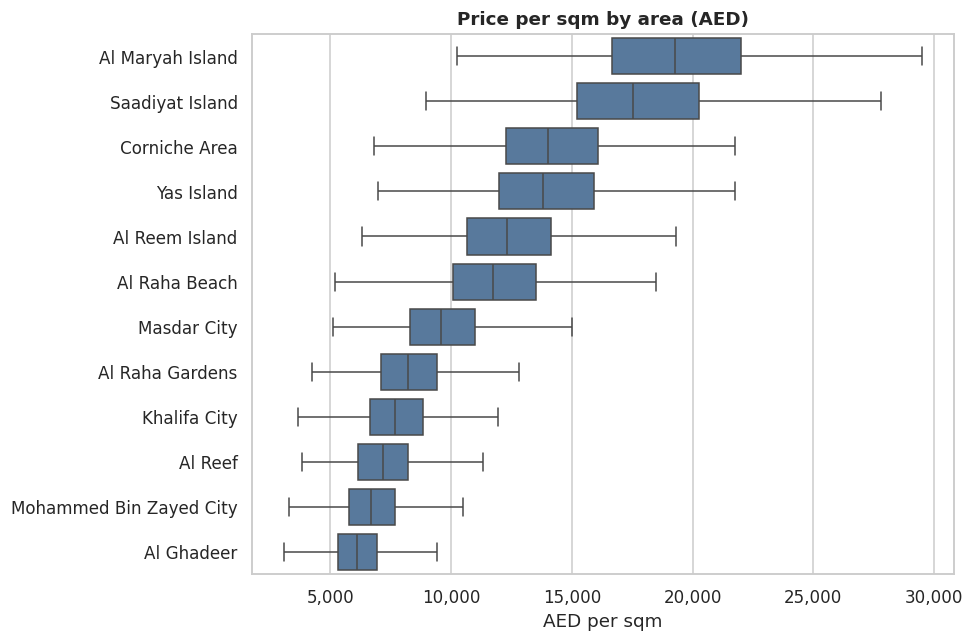

In [6]:
order = sales.groupby("area")["price_per_sqm"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=sales, y="area", x="price_per_sqm", order=order, showfliers=False, color="#4C78A8", ax=ax)
ax.set_title("Price per sqm by area (AED)"); ax.set_xlabel("AED per sqm"); ax.set_ylabel("")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout(); plt.savefig(FIG / "price_by_area.png"); plt.show()

### 4.2 Price trend over time

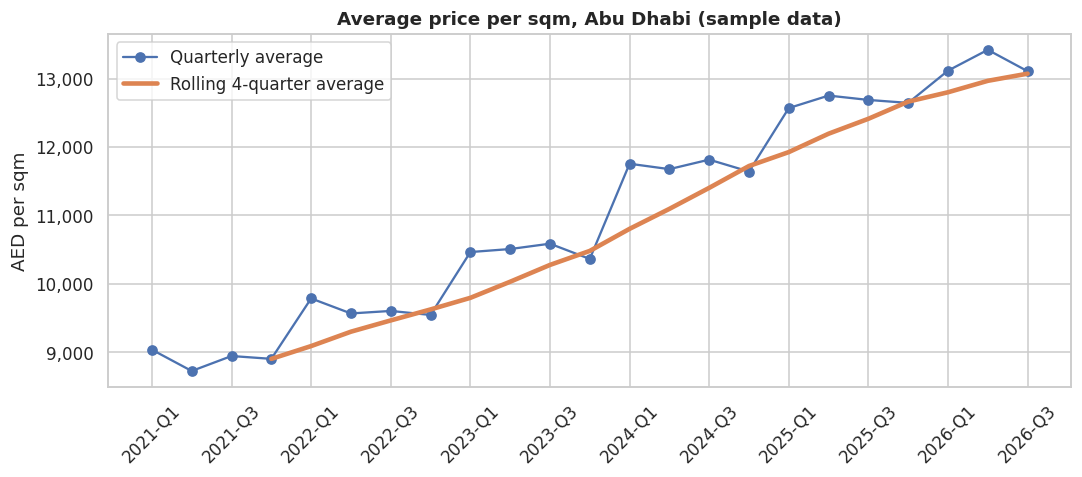

In [7]:
q = sales.groupby("year_quarter")["price_per_sqm"].mean()
roll = q.rolling(4).mean()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(q.index, q.values, marker="o", label="Quarterly average")
ax.plot(roll.index, roll.values, lw=3, label="Rolling 4-quarter average")
ax.set_title("Average price per sqm, Abu Dhabi (sample data)"); ax.set_ylabel("AED per sqm")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_xticks(range(0, len(q), 2)); ax.set_xticklabels(q.index[::2], rotation=45)
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "price_trend.png"); plt.show()

### 4.3 Seasonality of transactions

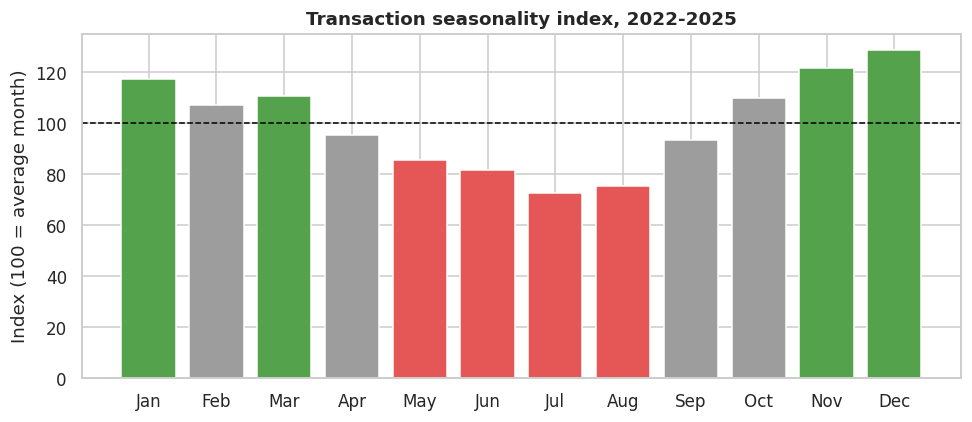

In [8]:
m = sales[sales["year"].between(2022, 2025)].groupby("month").size()
idx = 100 * m / m.mean()
fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#E45756" if v < 90 else "#54A24B" if v > 110 else "#9D9D9D" for v in idx]
ax.bar(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], idx.values, color=colors)
ax.axhline(100, color="black", lw=1, ls="--"); ax.set_ylabel("Index (100 = average month)")
ax.set_title("Transaction seasonality index, 2022-2025")
plt.tight_layout(); plt.savefig(FIG / "seasonality.png"); plt.show()

### 4.4 Rental yield vs price growth: where is the value?

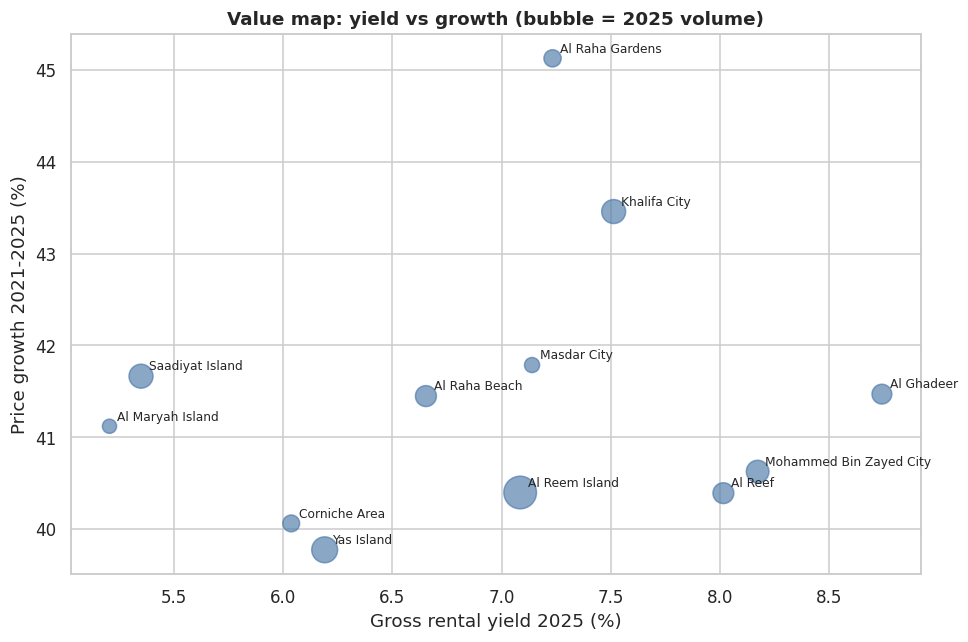

,area,gross_yield_pct,growth_21_25,transactions_2025
0,Al Ghadeer,8.74,41.47,670
9,Mohammed Bin Zayed City,8.17,40.63,876
4,Al Reef,8.02,40.39,744
7,Khalifa City,7.51,43.46,982
3,Al Raha Gardens,7.23,45.13,508
8,Masdar City,7.14,41.79,391
5,Al Reem Island,7.09,40.40,1828
2,Al Raha Beach,6.65,41.45,752
11,Yas Island,6.19,39.77,1149
6,Corniche Area,6.04,40.06,486


In [9]:
p25 = sales[sales.year == 2025].groupby(["area", "property_type"])["price_per_sqm"].mean()
r25 = rentals[rentals.year == 2025].groupby(["area", "property_type"])["rent_per_sqm"].mean()
yld = (100 * r25 / p25).groupby("area").mean().rename("gross_yield_pct")
g = sales.groupby(["area", "year"])["price_per_sqm"].mean().unstack()
growth = (100 * (g[2025] / g[2021] - 1)).rename("growth_21_25")
vol25 = sales[sales.year == 2025].groupby("area").size().rename("transactions_2025")
val = pd.concat([yld, growth, vol25], axis=1).reset_index()

fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(val["gross_yield_pct"], val["growth_21_25"], s=val["transactions_2025"] / 4, alpha=.65, color="#4C78A8")
for _, r in val.iterrows():
    ax.annotate(r["area"], (r["gross_yield_pct"], r["growth_21_25"]), fontsize=8, xytext=(5, 4), textcoords="offset points")
ax.set_xlabel("Gross rental yield 2025 (%)"); ax.set_ylabel("Price growth 2021-2025 (%)")
ax.set_title("Value map: yield vs growth (bubble = 2025 volume)")
plt.tight_layout(); plt.savefig(FIG / "value_map.png"); plt.show()
val.sort_values("gross_yield_pct", ascending=False).round(2)

### 4.5 Off-plan vs ready

In [10]:
sales[sales.year == 2025].pivot_table(index="property_type", columns="sale_type", values="price_per_sqm", aggfunc="mean").round(0)

sale_type,Off-Plan,Ready
property_type,,
Apartment,13489.0,13478.0
Townhouse,11905.0,12118.0
Villa,10918.0,11035.0


## 5. Takeaways (on sample data)
1. **Price tiers are wide:** Al Maryah and Saadiyat cost roughly 3x per sqm what Al Ghadeer does.
2. **Yield and price are inversely related:** the cheaper suburban areas (Al Ghadeer, MBZ City, Al Reef) have the highest gross yields; premium islands have the lowest.
3. **Seasonality is strong:** activity peaks in Nov-Jan and is weakest in Jul-Aug.
4. **No meaningful off-plan premium** appears in this dataset; confirm on real data before drawing conclusions.
5. **Next:** SQL deep dive (`sql/analysis_queries.sql`), Excel summary, Power BI dashboard.

**Limitations:** synthetic data; average prices are affected by property-mix changes; 2026 is a partial year; no controls for building quality or floor level.